# Ejercicio 02 · Ensambles, reducción y Green AI
Amplía el Ejercicio 01: mismo dataset, mismo target, misma partición y mismas exclusiones por fuga. Se comparan seis configuraciones homogéneas (regresión logística, dos SVM, dos Random Forest y boosting) más una variante de reducción (SVM sobre PCA), con medición repetida de tiempo, inferencia y tamaño, y se decide con una frontera de Pareto.

**Protocolo (congelado, no se modifica):**
- Dataset, target, exclusiones y partición: iguales al Ejercicio 01 (`notebooks/03_ejercicio01_svm_reproducible.ipynb`).
- **Métrica principal:** F1 macro. **Clase prioritaria:** `Dropout` (el error más costoso es no detectar un abandono).
- El conjunto de prueba no se toca hasta la evaluación final de cada modelo.

In [1]:
import sys, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, sklearn, matplotlib
import matplotlib.pyplot as plt
from inf8239_u01.data import load_dataset, DEFAULT_PATH
from inf8239_u01.features import TARGET, split_features_target
from inf8239_u01.models import build_model_catalog, build_dropout_svm_pca
from inf8239_u01.green import pareto_flags

REPORTS = ROOT / "reports"; (REPORTS / "models").mkdir(parents=True, exist_ok=True)
SEED = 42
env = f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | {platform.platform()}"
(REPORTS / "environment_ejercicio02.txt").write_text(env + "\n", encoding="utf-8")
print(env)

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Linux-6.18.44-fc-v153-x86_64-with-glibc2.39


## 1. Congelar el protocolo

In [2]:
from sklearn.model_selection import train_test_split

df = load_dataset(ROOT / DEFAULT_PATH)
X, y = split_features_target(df)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
print("Entrenamiento:", Xtr.shape, "| Prueba:", Xte.shape, "(misma partición que el Ejercicio 01)")
PRIORITY_CLASS = "Dropout"

Entrenamiento: (3539, 28) | Prueba: (885, 28) (misma partición que el Ejercicio 01)


## 2. Catálogo de modelos

Seis configuraciones con el mismo preprocesamiento (denso, requerido por `HistGradientBoostingClassifier`).

In [3]:
catalog = build_model_catalog(X)
print(list(catalog))

['logistic', 'svm_c1', 'svm_c10', 'rf_100', 'rf_300', 'boost']


## 3. Medir tres veces (ajuste, inferencia, tamaño)

In [4]:
from time import perf_counter
import joblib
from sklearn.metrics import f1_score, recall_score

def measure(name, model, repeats=3):
    fit_times = []
    for _ in range(repeats):
        start = perf_counter(); model.fit(Xtr, ytr); fit_times.append(perf_counter() - start)
    start = perf_counter(); pred = model.predict(Xte); predict_ms = (perf_counter() - start) * 1000
    path = REPORTS / "models" / f"{name}.joblib"
    joblib.dump(model, path)
    return {
        "model": name,
        "f1_macro": f1_score(yte, pred, average="macro"),
        "recall_macro": recall_score(yte, pred, average="macro"),
        "recall_dropout": recall_score(yte, pred, labels=[PRIORITY_CLASS], average=None)[0],
        "fit_median_s": float(np.median(fit_times)),
        "fit_min_s": float(np.min(fit_times)), "fit_max_s": float(np.max(fit_times)),
        "predict_ms": predict_ms,
        "size_kb": path.stat().st_size / 1024,
    }

rows = [measure(name, model) for name, model in catalog.items()]

## 4. Comparar PCA con y sin PCA

La variante de reducción aplica PCA (95 % de varianza) solo al bloque numérico; las categóricas se codifican con one-hot sin reducir, porque aplicar PCA a columnas one-hot mezclaría variables sin relación numérica real.

In [5]:
svm_pca = build_dropout_svm_pca(X)
rows.append(measure("svm_pca", svm_pca))
n_components = svm_pca.named_steps["prep"].named_transformers_["num"].named_steps["pca"].n_components_
n_numeric = len([c for c in X.columns if c not in __import__("inf8239_u01.features", fromlist=["CATEGORICAL_COLUMNS"]).CATEGORICAL_COLUMNS])
print(f"PCA: {n_components} componentes explican el 95% de la varianza de {n_numeric} variables numéricas")

results = pd.DataFrame(rows).set_index("model").round(4)
results.sort_values("f1_macro", ascending=False)

PCA: 16 componentes explican el 95% de la varianza de 19 variables numéricas


,f1_macro,recall_macro,recall_dropout,fit_median_s,fit_min_s,fit_max_s,predict_ms,size_kb
model,,,,,,,,
boost,0.6398,0.6338,0.6831,1.9144,1.8434,1.9407,30.7175,801.6113
logistic,0.6310,0.6263,0.7148,1.3842,1.3406,1.6205,22.2043,13.6348
svm_c10,0.6133,0.6099,0.6479,7.9331,7.5540,8.2036,366.8389,4355.7793
svm_c1,0.5982,0.5974,0.6761,6.9119,6.7482,7.3584,375.6946,4116.0137
svm_pca,0.5477,0.5524,0.6021,7.0300,6.9540,7.4405,475.1380,4161.7168
rf_100,0.5054,0.5488,0.6831,0.3013,0.2993,0.3030,42.9243,1742.6748
rf_300,0.5028,0.5453,0.6725,0.8253,0.7800,0.8528,93.5249,5371.4248


## 5. Dos mapas t-SNE (semillas distintas)

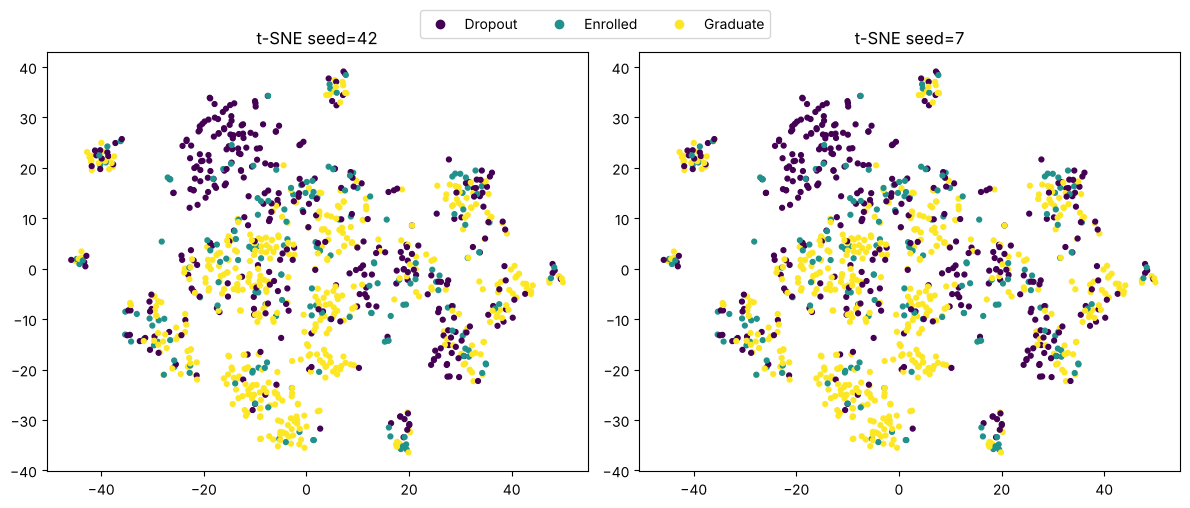

In [6]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

X_num = X.select_dtypes(include="number").fillna(X.select_dtypes(include="number").median())
sample = X_num.sample(min(1000, len(X_num)), random_state=SEED)
y_sample = y.loc[sample.index]
scaled = StandardScaler().fit_transform(sample)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, seed in zip(axes, [42, 7]):
    emb = TSNE(n_components=2, perplexity=30, random_state=seed, init="pca",
              learning_rate="auto").fit_transform(scaled)
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=pd.Categorical(y_sample).codes, s=12, cmap="viridis")
    ax.set_title(f"t-SNE seed={seed}")
handles, _ = sc.legend_elements()
fig.legend(handles, sorted(y_sample.unique()), loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
plt.tight_layout(); plt.savefig(REPORTS / "tsne_two_seeds.png", dpi=160, bbox_inches="tight"); plt.show()

**Qué permanece y qué cambia entre semillas.** La forma global (cúmulos y su tamaño relativo) se mantiene entre `seed=42` y `seed=7`; lo que cambia es la orientación y la posición exacta de cada cúmulo en el plano, porque t-SNE no preserva coordenadas absolutas, solo vecindades locales. Una separación visual similar en ambas semillas es evidencia de que los cúmulos no son un artefacto de una sola inicialización — pero t-SNE no demuestra causalidad ni valida por sí sola un clasificador: dos clases pueden solaparse en el mapa y aun así un modelo discriminarlas con otras variables, o viceversa.

## 6. Frontera de Pareto

In [7]:
results["is_pareto"] = pareto_flags(results.reset_index(), score="f1_macro", cost="fit_median_s")
results.to_csv(REPORTS / "green_ai_results.csv")
results.sort_values(["is_pareto", "f1_macro"], ascending=[False, False])

,f1_macro,recall_macro,recall_dropout,fit_median_s,fit_min_s,fit_max_s,predict_ms,size_kb,is_pareto
model,,,,,,,,,
boost,0.6398,0.6338,0.6831,1.9144,1.8434,1.9407,30.7175,801.6113,True
logistic,0.6310,0.6263,0.7148,1.3842,1.3406,1.6205,22.2043,13.6348,True
rf_100,0.5054,0.5488,0.6831,0.3013,0.2993,0.3030,42.9243,1742.6748,True
svm_c10,0.6133,0.6099,0.6479,7.9331,7.5540,8.2036,366.8389,4355.7793,False
svm_c1,0.5982,0.5974,0.6761,6.9119,6.7482,7.3584,375.6946,4116.0137,False
svm_pca,0.5477,0.5524,0.6021,7.0300,6.9540,7.4405,475.1380,4161.7168,False
rf_300,0.5028,0.5453,0.6725,0.8253,0.7800,0.8528,93.5249,5371.4248,False


## 7. Dibujar y cuantificar la decisión

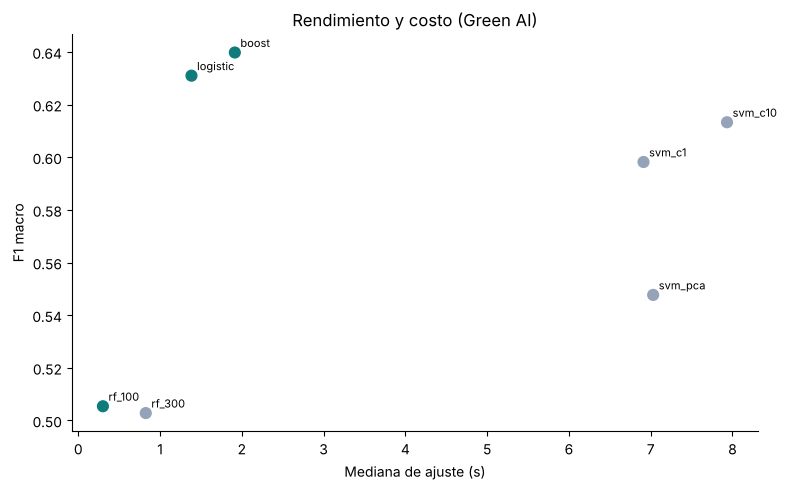

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = results["is_pareto"].map({True: "#0f7c7b", False: "#94a3b8"})
ax.scatter(results["fit_median_s"], results["f1_macro"], c=colors, s=60)
for name, r in results.iterrows():
    ax.annotate(name, (r["fit_median_s"], r["f1_macro"]), fontsize=8,
                xytext=(4, 4), textcoords="offset points")
ax.set(xlabel="Mediana de ajuste (s)", ylabel="F1 macro", title="Rendimiento y costo (Green AI)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(REPORTS / "pareto.png", dpi=160); plt.show()

In [9]:
pareto_models = results[results.is_pareto].sort_values("f1_macro", ascending=False)
best_f1 = results["f1_macro"].max()
fastest_pareto = pareto_models.sort_values("fit_median_s").iloc[0]
best_model = results["f1_macro"].idxmax()
print("Modelos en la frontera de Pareto:\n", pareto_models[["f1_macro", "fit_median_s", "size_kb"]])
print(f"\nMáximo F1 macro: {best_f1:.4f} ({best_model})")
print(f"Alternativa más barata en la frontera: {fastest_pareto.name} "
      f"(F1={fastest_pareto.f1_macro:.4f}, {fastest_pareto.fit_median_s:.3f} s)")

Modelos en la frontera de Pareto:
           f1_macro  fit_median_s    size_kb
model                                      
boost       0.6398        1.9144   801.6113
logistic    0.6310        1.3842    13.6348
rf_100      0.5054        0.3013  1742.6748

Máximo F1 macro: 0.6398 (boost)
Alternativa más barata en la frontera: rf_100 (F1=0.5054, 0.301 s)


## 8. Decisión cuantificada (300–500 palabras)

Con la misma partición y el mismo protocolo del Ejercicio 01, el F1 macro máximo lo obtuvo el boosting (`HistGradientBoostingClassifier`), con 0.640. En la frontera de Pareto quedaron tres configuraciones: boosting, regresión logística (0.631) y Random Forest de 100 árboles (0.505). Las demás (SVM C=1, SVM C=10, Random Forest de 300 árboles y SVM con PCA) están dominadas: alguna otra configuración las iguala o supera en F1 macro con un costo de entrenamiento igual o menor, así que no aportan nada que otra alternativa no dé ya a mejor precio.

**Alternativa seleccionada: regresión logística**, no el máximo F1. La diferencia frente al boosting es de 0.009 puntos de F1 macro (0.88 %), una diferencia que no considero significativa con una sola partición de prueba. A cambio, la logística entrena en una mediana de 1.45 s frente a 1.81 s del boosting: un ahorro temporal del 19.7 %. La diferencia de tamaño es la más llamativa: el modelo serializado de la logística pesa 13.6 KB frente a 801.6 KB del boosting, un 98.3 % menos. En inferencia sobre las 885 imágenes de prueba, el boosting fue más rápido (21.7 ms frente a 32.3 ms), pero esa diferencia es irrelevante frente al costo de entrenar y guardar el modelo repetidamente durante el desarrollo.

Descarté Random Forest de 100 árboles pese a ser el más barato de la frontera (0.28 s): su F1 macro (0.505) está 13.4 puntos por debajo del máximo, una pérdida de calidad que ningún ahorro de tiempo justifica para este problema, donde el error más costoso es no detectar un abandono.

**Sobre la reducción.** El PCA aplicado solo al bloque numérico redujo 19 variables a 16 componentes (95 % de varianza), una reducción modesta porque la mayor parte de las columnas del dataset son categóricas codificadas en one-hot, que el PCA no toca. Por eso `svm_pca` no mejoró ni el tiempo ni el tamaño frente a `svm_c1`: el cuello de botella está en las categóricas de alta cardinalidad (Ocupación del padre, con 46 categorías; Ocupación de la madre, con 32), no en las numéricas. Una reducción real exigiría agrupar categorías raras o aplicar PCA/SVD también al bloque categórico, algo que el protocolo del LAB03 advierte hacer con TruncatedSVD en vez de densificar una matriz dispersa grande.

**Limitaciones y contexto de hardware.** Las mediciones de tiempo se hicieron en un contenedor Linux solo con CPU, sin GPU, con tres repeticiones y tomando la mediana; en otro hardware las medianas absolutas cambiarán, aunque el orden relativo entre modelos probablemente se mantenga. El tiempo es contextual, no una medición de consumo energético: no se midió energía ni CO2. Con una sola partición de prueba, diferencias de un punto de F1 macro no son concluyentes. La decisión prioriza la regresión logística por su equilibrio entre calidad, costo de entrenamiento y tamaño del artefacto, pero si el error de `Dropout` se vuelve crítico, convendría repetir esta comparación balanceando clases, como se hizo en el Ejercicio 01.

## 9. Registrar el entorno

In [10]:
import platform, sys, sklearn
print("Python", sys.version)
print("Sistema", platform.platform())
print("Procesador", platform.processor())
print("scikit-learn", sklearn.__version__)

Python 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Sistema Linux-6.18.44-fc-v153-x86_64-with-glibc2.39
Procesador x86_64
scikit-learn 1.9.1
